### Import libraries

In [73]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import pandas as pd
import sys

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))
from src.preprocessing import create_dataset, IMG_SIZE, BATCH_SIZE

import os

from tensorflow.keras.models import load_model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

### Load trained models

In [74]:
custom_cnn = tf.keras.models.load_model(
    "../models/custom_cnn.keras"
)

mobilenet = tf.keras.models.load_model(
    "../models/mobilenetv2.keras"
)

print("Both models loaded successfully!")

Both models loaded successfully!


### Define paths and classes

In [75]:
DATA_PATH = PROJECT_ROOT / "dataset" / "processed"
MODEL_PATH = PROJECT_ROOT / "models"
GRAPH_PATH = PROJECT_ROOT / "results" / "graphs"

MODEL_PATH.mkdir(parents=True, exist_ok=True)
GRAPH_PATH.mkdir(parents=True, exist_ok=True)

CLASSES = [
    "Tomato_Bacterial_spot",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_Leaf_Mold",
    "Tomato_healthy"
]

NUM_CLASSES = len(CLASSES)

print("Number of classes:", NUM_CLASSES)

Number of classes: 5


### Load CSV files

In [76]:
train_df = pd.read_csv(DATA_PATH / "train.csv")
validation_df = pd.read_csv(DATA_PATH / "validation.csv")
test_df = pd.read_csv(DATA_PATH / "test.csv")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("Testing images:", len(test_df))

Training images: 5305
Validation images: 1137
Testing images: 1137


### Load test dataset

In [77]:
train_dataset = create_dataset(
    train_df,
    CLASSES,
    training=True
)

validation_dataset = create_dataset(
    validation_df,
    CLASSES,
    training=False
)

test_dataset = create_dataset(
    test_df,
    CLASSES,
    training=False
)

print("Training dataset:", train_dataset)
print("Validation dataset:", validation_dataset)
print("Testing dataset:", test_dataset)

Training dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>
Validation dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>
Testing dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


### Prepare test datasets

In [78]:
test_dataset_custom = test_dataset

test_dataset_mobilenet = test_dataset.map(
    lambda x, y: (
        preprocess_input(x * 255.0),
        y
    )
)

### Create prediction function

In [79]:
def get_predictions(model, dataset):

    y_true = []
    y_pred = []

    for images, labels in dataset:

        predictions = model.predict(
            images,
            verbose=0
        )

        y_true.extend(labels.numpy())
        y_pred.extend(
            np.argmax(predictions, axis=1)
        )

    return np.array(y_true), np.array(y_pred)

### Generate predictions

In [80]:
y_true, y_pred_custom = get_predictions(
    custom_cnn,
    test_dataset_custom
)

_, y_pred_mobile = get_predictions(
    mobilenet,
    test_dataset_mobilenet
)

print("Predictions generated successfully!")

Predictions generated successfully!


### Evaluate model performance

In [81]:
def evaluate_model(y_true, y_pred, model_name):

    print(f"\n========== {model_name} ==========")

    print("Accuracy:",
          accuracy_score(y_true, y_pred))

    print("Precision:",
          precision_score(
              y_true, y_pred,
              average="weighted",
              zero_division=0
          ))

    print("Recall:",
          recall_score(
              y_true, y_pred,
              average="weighted",
              zero_division=0
          ))

    print("F1 Score:",
          f1_score(
              y_true, y_pred,
              average="weighted",
              zero_division=0
          ))

    print("\nClassification Report:")

    print(classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASSES,
        zero_division=0
    ))

In [82]:
evaluate_model(
    y_true,
    y_pred_custom,
    "Custom CNN"
)




========== Custom CNN ==========
Accuracy: 0.7590149516270889
Precision: 0.8020691916630096
Recall: 0.7590149516270889
F1 Score: 0.7584364868187119

Classification Report:
                       precision    recall  f1-score   support

Tomato_Bacterial_spot       0.99      0.65      0.78       319
  Tomato_Early_blight       0.68      0.65      0.66       150
   Tomato_Late_blight       0.86      0.67      0.75       287
     Tomato_Leaf_Mold       0.60      0.89      0.72       143
       Tomato_healthy       0.68      1.00      0.81       238

             accuracy                           0.76      1137
            macro avg       0.76      0.77      0.75      1137
         weighted avg       0.80      0.76      0.76      1137



In [83]:
evaluate_model(
    y_true,
    y_pred_mobile,
    "MobileNetV2"
)


========== MobileNetV2 ==========
Accuracy: 0.9542656112576957
Precision: 0.954085362455008
Recall: 0.9542656112576957
F1 Score: 0.9530152333557432

Classification Report:
                       precision    recall  f1-score   support

Tomato_Bacterial_spot       0.94      1.00      0.97       319
  Tomato_Early_blight       0.94      0.79      0.86       150
   Tomato_Late_blight       0.97      0.96      0.96       287
     Tomato_Leaf_Mold       0.96      0.94      0.95       143
       Tomato_healthy       0.97      1.00      0.99       238

             accuracy                           0.95      1137
            macro avg       0.95      0.94      0.94      1137
         weighted avg       0.95      0.95      0.95      1137



### Generate confusion matrices

In [68]:
def plot_confusion_matrix(y_true, y_pred, model_name):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES)
    )

    plt.figure(figsize=(10, 8))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASSES,
        yticklabels=CLASSES
    )

    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    filename = model_name.lower().replace(" ", "_")

    plt.savefig(
        f"../results/{filename}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

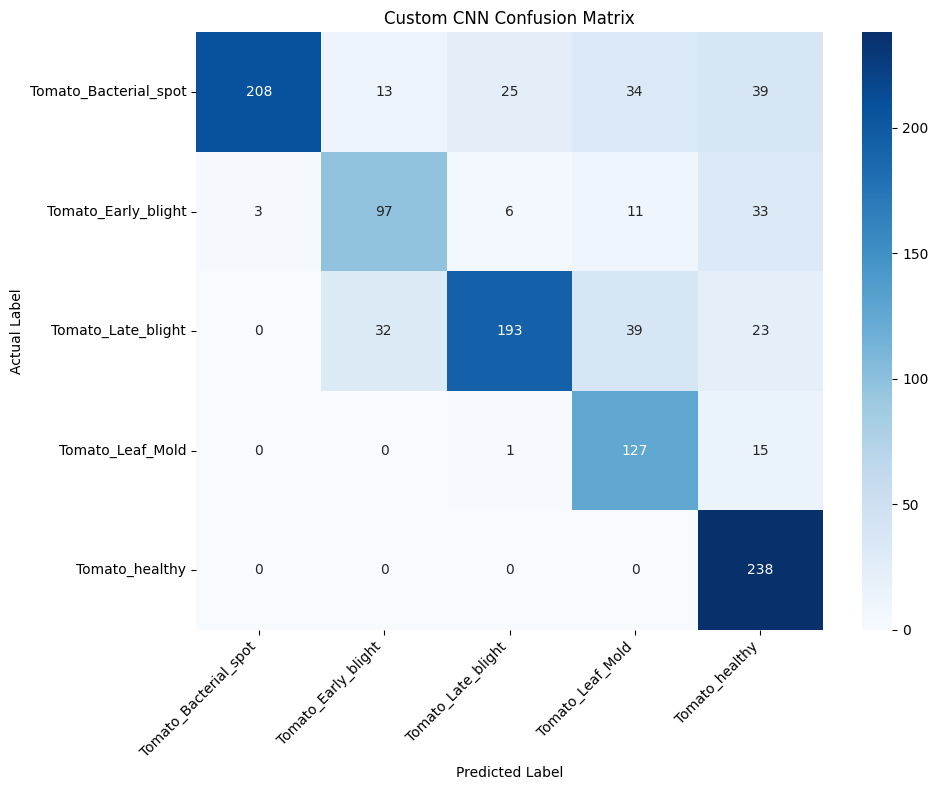

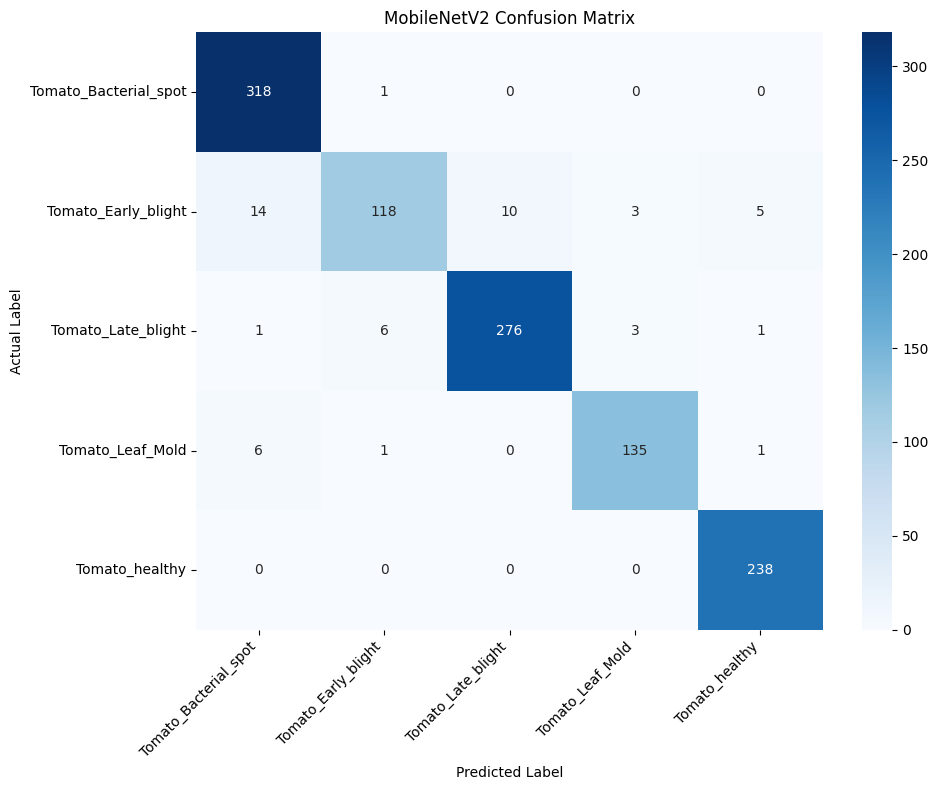

In [69]:
os.makedirs("../results", exist_ok=True)

plot_confusion_matrix(
    y_true,
    y_pred_custom,
    "Custom CNN"
)

plot_confusion_matrix(
    y_true,
    y_pred_mobile,
    "MobileNetV2"
)

### Compare both models

In [70]:
comparison_df = pd.DataFrame({

    "Model": ["Custom CNN", "MobileNetV2"],

    "Accuracy": [
        accuracy_score(y_true, y_pred_custom),
        accuracy_score(y_true, y_pred_mobile)
    ],

    "Precision": [
        precision_score(
            y_true, y_pred_custom,
            average="weighted", zero_division=0
        ),
        precision_score(
            y_true, y_pred_mobile,
            average="weighted", zero_division=0
        )
    ],

    "Recall": [
        recall_score(
            y_true, y_pred_custom,
            average="weighted", zero_division=0
        ),
        recall_score(
            y_true, y_pred_mobile,
            average="weighted", zero_division=0
        )
    ],

    "F1 Score": [
        f1_score(
            y_true, y_pred_custom,
            average="weighted", zero_division=0
        ),
        f1_score(
            y_true, y_pred_mobile,
            average="weighted", zero_division=0
        )
    ]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Custom CNN,0.759015,0.802069,0.759015,0.758436
1,MobileNetV2,0.954266,0.954085,0.954266,0.953015


In [71]:
os.makedirs("../results/graphs", exist_ok=True)

comparison_df.to_csv(
    "../results/model_comparison.csv",
    index=False
)

### Accuracy comparison graph

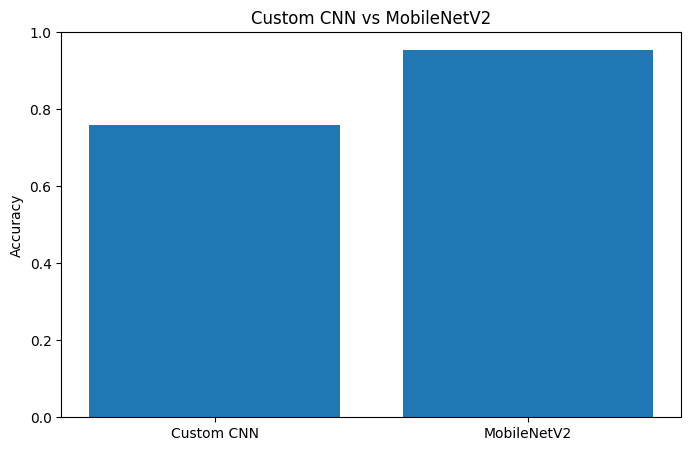

In [72]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"]
)

plt.title("Custom CNN vs MobileNetV2")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.savefig(
    "../results/graphs/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()